# Entregable II — Búsqueda de un mejor modelo y validación externa

Modelos y Simulación de Sistemas II — Universidad de Antioquia — Grupo 14

Con el modelo base del notebook 03 (AUC de validación ≈ 0,80 y de prueba ≈ 0,76 a 0,79) se
probaron cuatro maneras de mejorarlo, todas con **el mismo protocolo temporal** (K = 8, H = 12,
X = 14; validación de ventana expansiva; prueba usada una sola vez). Después se evaluó el modelo
de Cartagena en otras dos sedes. Los experimentos se corren desde `experimentos/` y este
cuaderno solo lee sus resultados (`reports/`).

1. Variables de **trayectoria** (cómo termina la ventana de observación).
2. **Ajuste de hiperparámetros** y **ensamble**.
3. Información **nueva de la base**: gestión de cobranza y justificaciones (solo eventos con fecha ≤ semana K).
4. **Validación externa** en Sincelejo y Montería.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
R = Path("../reports") if Path("../reports").exists() else Path("reports")
pd.options.display.float_format = "{:.3f}".format

## 1. Variables de trayectoria

Últimas dos semanas de la ventana, tendencia y desviación del atraso, cambio entre mitades, días desde el último pago, mayor hueco entre pagos y dinero pagado en las últimas dos semanas.

In [2]:
t = pd.read_csv(R / "mejora_trayectoria.csv")
display(t)

,modelo,vars,AUC val,sd,AUC prueba,BACC prueba,MCC prueba
0,Regresión logística,base,0.805,0.016,0.756,0.686,0.367
1,Regresión logística,+trayectoria,0.800,0.013,0.761,0.680,0.359
2,KNN,base,0.782,0.020,0.701,0.676,0.361
3,KNN,+trayectoria,0.791,0.022,0.743,0.676,0.368
4,Árbol de decisión,base,0.741,0.040,0.759,0.657,0.376
5,Árbol de decisión,+trayectoria,0.743,0.032,0.689,0.662,0.389
6,Random Forest,base,0.798,0.019,0.784,0.703,0.421
7,Random Forest,+trayectoria,0.794,0.025,0.790,0.711,0.431
8,Gradient Boosting,base,0.784,0.022,0.783,0.693,0.399
9,Gradient Boosting,+trayectoria,0.782,0.023,0.782,0.696,0.396


Las diferencias (|ΔAUC| ≤ 0,01 en validación en los modelos principales) quedan dentro de la desviación entre pliegues (≈ 0,02): la trayectoria no aporta información que las variables base no tengan.

## 2. Ajuste de hiperparámetros y ensamble

La configuración se elige solo con el AUC de validación temporal; la prueba se reporta pero no decide.

In [3]:
a = pd.read_csv(R / "ajuste_hiperparametros.csv")
a["familia"] = a.modelo.str.split().str[0]
display(a.sort_values("AUC val", ascending=False).groupby("familia").head(3).sort_values(["familia", "AUC val"], ascending=[True, False]))

,modelo,AUC val,sd,AUC prueba,BACC prueba,MCC prueba,familia
28,GB n=100 d=2 lr=0.02,0.790,0.023,0.786,0.716,0.431,GB
30,GB n=100 d=3 lr=0.02,0.787,0.019,0.782,0.695,0.411,GB
32,GB n=200 d=2 lr=0.02,0.787,0.025,0.788,0.701,0.404,GB
9,LR C=2.0 l1,0.810,0.019,0.754,0.689,0.369,LR
8,LR C=2.0 l2,0.806,0.017,0.754,0.694,0.382,LR
6,LR C=0.5 l2,0.805,0.016,0.756,0.686,0.367,LR
10,RF depth=4 leaf=5 mf=sqrt,0.802,0.020,0.791,0.719,0.436,RF
18,RF depth=6 leaf=15 mf=sqrt,0.801,0.021,0.791,0.701,0.415,RF
12,RF depth=4 leaf=15 mf=sqrt,0.800,0.022,0.791,0.719,0.439,RF


In [4]:
e = pd.read_csv(R / "mejora_ensamble.csv")
display(e)

,modelo,AUC val,sd,AUC prueba,BACC prueba,MCC prueba,precision top10%,precision top20%,precision top30%,base prueba
0,LR,0.805,0.016,0.756,0.686,0.367,0.776,0.741,0.678,0.387
1,RF,0.802,0.020,0.791,0.719,0.436,0.793,0.741,0.718,0.387
2,Ensamble,0.811,0.023,0.788,0.707,0.411,0.793,0.750,0.713,0.387


El mejor ajuste mejora el AUC de validación en menos de 0,01 y el ensamble (voto suave de logística, Random Forest y Gradient Boosting) queda igual que Random Forest solo. La precisión en el top-k es la métrica de uso práctico: si la empresa revisara solo el 10 % de episodios con mayor riesgo, acertaría cerca de 8 de cada 10 (tasa base ≈ 39 %).

## 3. Información nueva de la base

`np_justi_super` (justificaciones) y `np_gestion` (gestión de cobranza), solo lectura y anonimizadas. Se cuentan los eventos con fecha entre el inicio y la semana K; el estado aprobado/rechazado se ignora porque la empresa lo actualiza después (fuga). `tests/test_ciclos.py` verifica que eventos posteriores a K no cambian las variables.

In [5]:
g = pd.read_csv(R / "mejora_gestion.csv")
display(g)

,modelo,vars,AUC val,sd,AUC prueba,BACC,MCC
0,Regresión logística,base,0.805,0.016,0.756,0.686,0.367
1,Regresión logística,+gestion,0.789,0.028,0.764,0.712,0.421
2,KNN,base,0.782,0.020,0.701,0.676,0.361
3,KNN,+gestion,0.756,0.013,0.718,0.646,0.298
4,Árbol de decisión,base,0.741,0.040,0.759,0.657,0.376
5,Árbol de decisión,+gestion,0.738,0.039,0.759,0.657,0.376
6,Random Forest,base,0.798,0.019,0.784,0.703,0.421
7,Random Forest,+gestion,0.795,0.020,0.788,0.709,0.422
8,Gradient Boosting,base,0.784,0.022,0.783,0.693,0.399
9,Gradient Boosting,+gestion,0.785,0.021,0.794,0.721,0.441


Las variables se asocian con la etiqueta (p. ej. más registros de justificación y cuotas dobles en los episodios de riesgo), pero repiten lo que ya dicen los pagos: no mejoran la validación. Además `np_gestion` casi no tiene registros en 2024.

## 4. Validación externa: entrenar en Cartagena, probar en otras sedes

Sincelejo y Montería usan la misma estructura de base en otros servidores. El modelo se entrena con todos los episodios de Cartagena y predice, sin reajustarse, los de cada sede (cohorte desde su primer pago registrado).

,modelo,sede,n,pos,AUC,top10,top20
0,Regresión logística,Sincelejo,793,0.236,0.767,0.759,0.576
1,Regresión logística,Montería,199,0.211,0.783,0.684,0.513
2,Random Forest,Sincelejo,793,0.236,0.754,0.709,0.563
3,Random Forest,Montería,199,0.211,0.805,0.684,0.513
4,Gradient Boosting,Sincelejo,793,0.236,0.761,0.709,0.557
5,Gradient Boosting,Montería,199,0.211,0.795,0.684,0.538


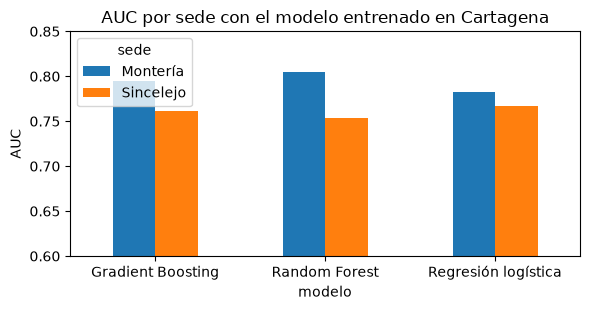

In [6]:
s = pd.read_csv(R / "validacion_externa_sedes.csv")
display(s[s.vars == "con empresa"].drop(columns="vars"))
fig, ax = plt.subplots(figsize=(6, 3.2))
p = s[s.vars == "con empresa"].pivot(index="modelo", columns="sede", values="AUC")
p.plot.bar(ax=ax, rot=0); ax.set_ylim(0.6, 0.85); ax.set_ylabel("AUC"); ax.set_title("AUC por sede con el modelo entrenado en Cartagena")
plt.tight_layout(); plt.show()

El AUC en las otras sedes (0,75 a 0,81) es igual o mayor que el de la prueba temporal de Cartagena, aunque su tasa de riesgo es menor (21 a 24 % frente a 36 %). Quitar `empresa` apenas cambia el resultado (±0,003): en las sedes nuevas todos los episodios son MOTOHOY. Montería tiene solo 199 episodios, por lo que su cifra es menos precisa; la conclusión se apoya sobre todo en Sincelejo.

## Conclusión

Ninguna de las cuatro vías de mejora aumenta el AUC más allá del ruido de la validación: con la información de las primeras K semanas el modelo ya está cerca de su máximo. El resultado más sólido es que **el modelo generaliza a otras sedes sin reajustarse**. El umbral de decisión, en cambio, debería calibrarse por sede porque la tasa de riesgo cambia.